# Komatsuna analysis

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path
from matplotlib.lines import Line2D

from finsler_learning.shepplogan_pipeline.aggregate_shepplogan_results import (
    METHODS,
    BASE_METHODS,
    collect_base_geometry_metrics,
    collect_base_geometry_quality,
    merge_base_geometry_table,
    base_latex_table,
    collect_biased_extrapolation,
    merge_biased_extrapolation_table,
    biased_extrapolation_latex_table,
)

sns.set_context("notebook")
plt.rcParams["figure.figsize"] = (10, 6)
base_path = Path("/home/tblanchard/phd/finsler_learning/results/komatsuna/runs_2026-11-11")

/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Base setup: recovered data

In [2]:
df_inter, df_extra = collect_base_geometry_metrics(base_path, BASE_METHODS)
df_quality_inter, df_quality_extra = collect_base_geometry_quality(base_path, BASE_METHODS)
df_inter.head()

Interpolation metrics missing for Wasserstein, Finsler=False: [Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/komatsuna/runs_2026-11-11/geodesic_evaluation_wasserstein/geo_kendall_tau_list_test.pth'
Interpolation metrics missing for Wasserstein, Finsler=True: [Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/komatsuna/runs_2026-11-11/geodesic_evaluation_wasserstein_randers/geo_kendall_tau_list_test.pth'
Extrapolation metrics missing for Wasserstein, Finsler=True: [Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/komatsuna/runs_2026-11-11/extrapolation_evaluation_wasserstein_randers/extrapolation_kendall_tau_test.pth'
Interpolation metrics missing for HyperSpherical, Finsler=True: [Errno 2] No such file or directory: '/home/tblanchard/phd/finsler_learning/results/komatsuna/runs_2026-11-11/geodesic_evaluation_spherical_randers/geo_kendall_tau_list_test.pth'
Extrapolation metrics missin

,Geodesic Distance,Kendall Tau,Base Metric,Finsler
0,17.133168,0.913333,Euclidean,False
1,12.775111,1.000000,Euclidean,False
2,13.028180,1.000000,Euclidean,False
3,13.822526,1.000000,Euclidean,False
4,18.933321,0.797998,Euclidean,False


## Interpolation

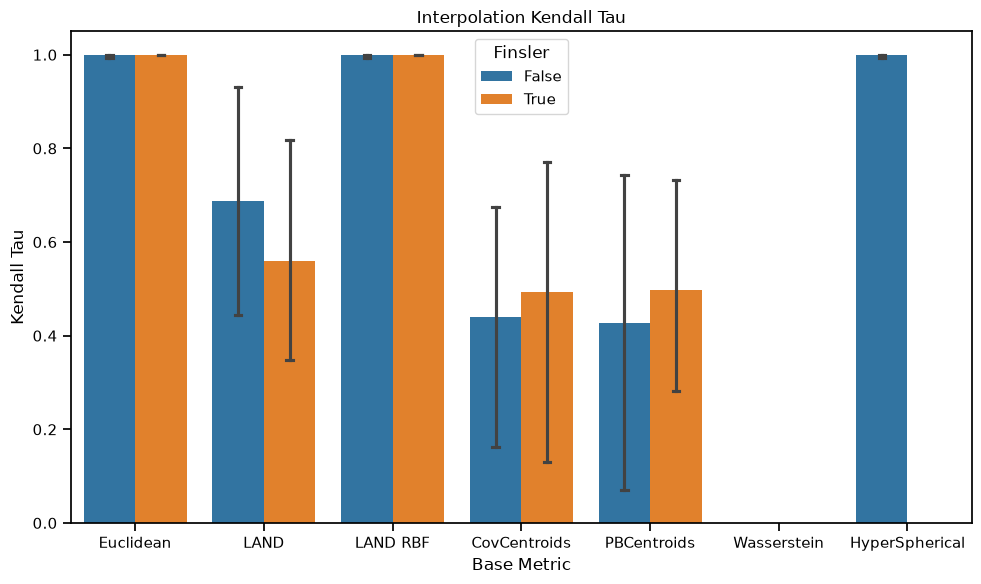

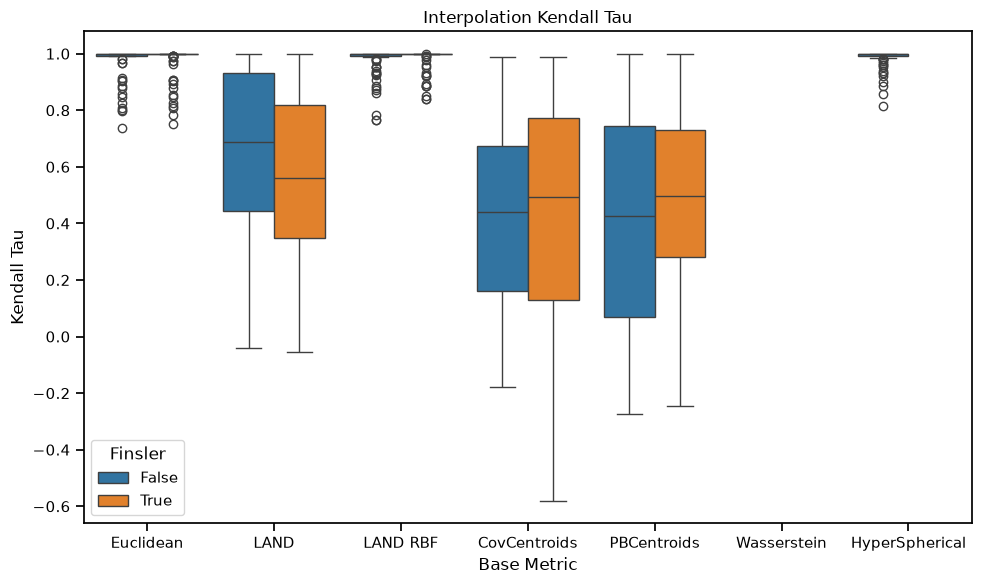

In [3]:
method_names = [name for name, _ in BASE_METHODS]

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_inter,
    x="Base Metric",
    y="Kendall Tau",
    hue="Finsler",
    order=method_names,
    estimator="median",
    errorbar=("pi", 50),
    capsize=0.1,
    ax=ax,
)
ax.set_title("Interpolation Kendall Tau")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.boxplot(
    data=df_inter,
    x="Base Metric",
    y="Kendall Tau",
    hue="Finsler",
    order=method_names,
    ax=ax,
)
ax.set_title("Interpolation Kendall Tau")
plt.tight_layout()
plt.show()

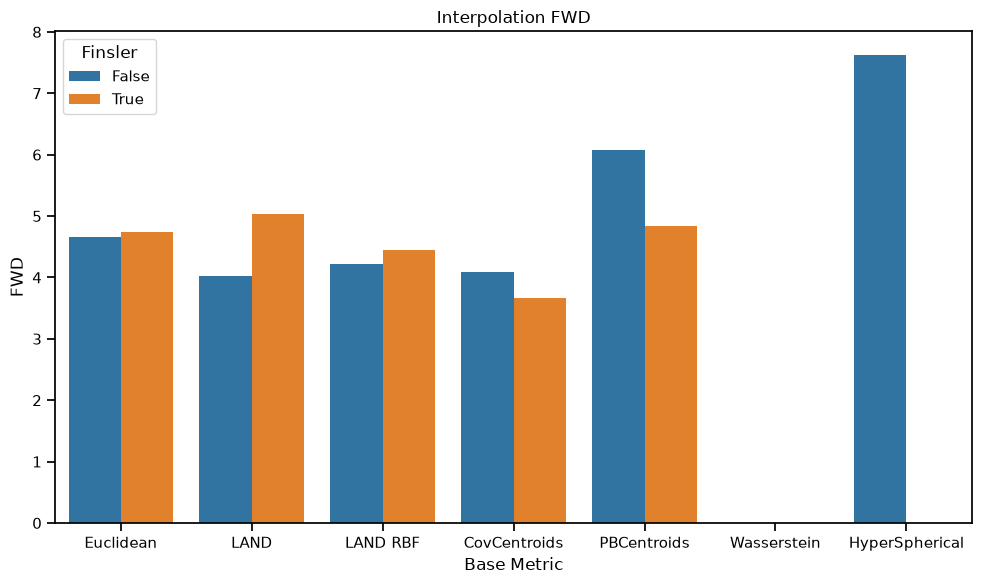

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_quality_inter,
    x="Base Metric",
    y="FWD",
    hue="Finsler",
    order=method_names,
    ax=ax,
    errorbar=None,
)
ax.set_title("Interpolation FWD")
plt.tight_layout()
plt.show()

## Extrapolation

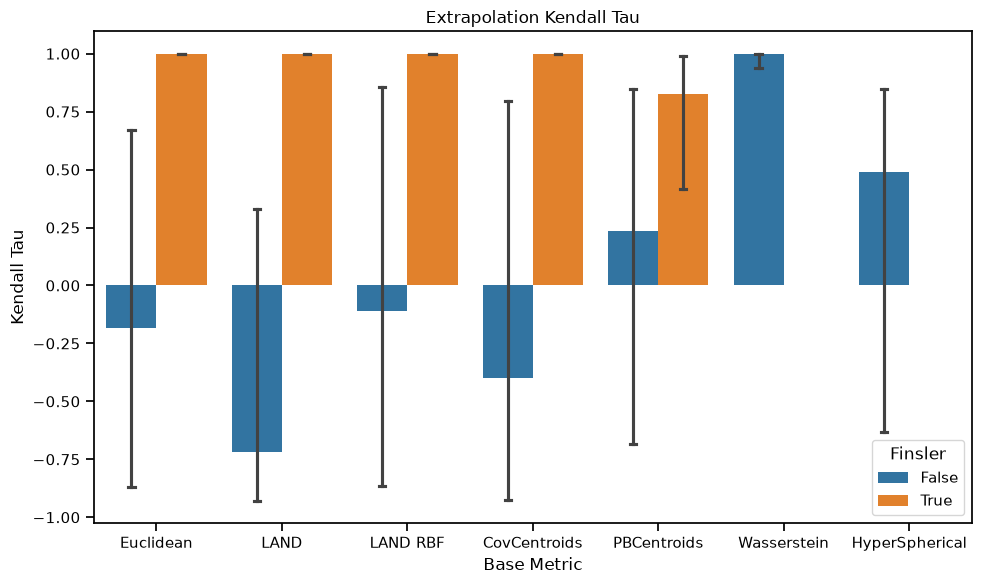

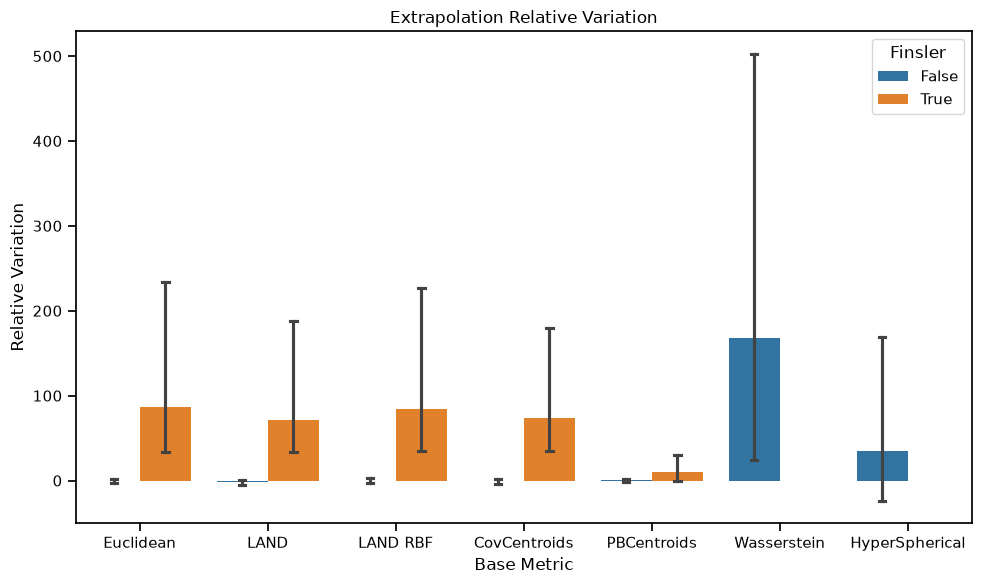

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_extra,
    x="Base Metric",
    y="Kendall Tau",
    hue="Finsler",
    order=method_names,
    estimator="median",
    errorbar=("pi", 50),
    capsize=0.1,
    ax=ax,
)
ax.set_title("Extrapolation Kendall Tau")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_extra,
    x="Base Metric",
    y="Relative Variation",
    hue="Finsler",
    order=method_names,
    estimator="median",
    errorbar=("pi", 50),
    capsize=0.1,
    ax=ax,
)
ax.set_title("Extrapolation Relative Variation")
plt.tight_layout()
plt.show()

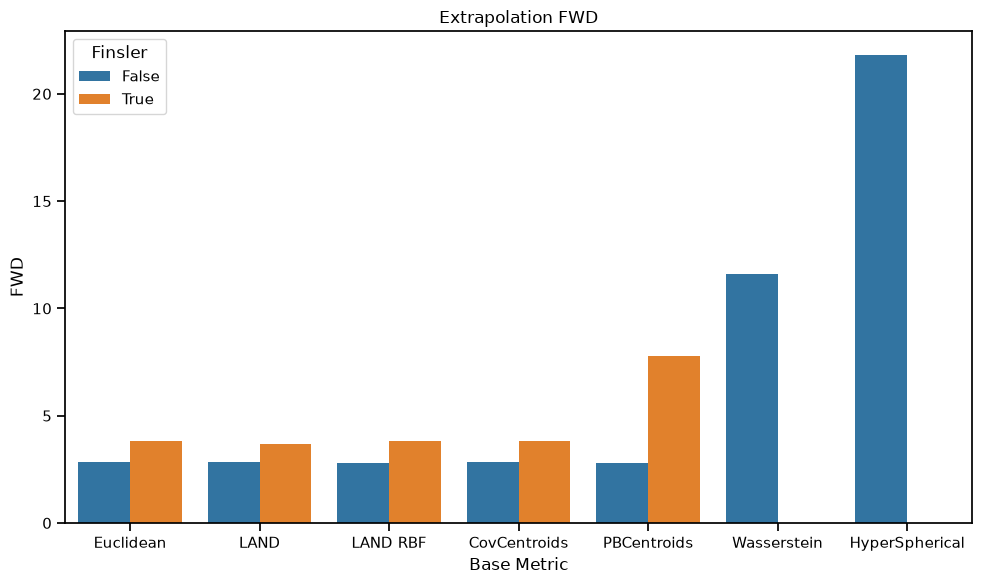

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.barplot(
    data=df_quality_extra,
    x="Base Metric",
    y="FWD",
    hue="Finsler",
    order=method_names,
    ax=ax,
    errorbar=None,
)
ax.set_title("Extrapolation FWD")
plt.tight_layout()
plt.show()

## Combined base results

In [7]:
combined = merge_base_geometry_table(
    df_inter,
    df_extra,
    df_quality_inter,
    df_quality_extra,
)
combined

,Base Metric,Finsler,Kendall Tau Median Inter,Kendall Tau IQR Inter,Kendall Tau Median Extra,Kendall Tau IQR Extra,Relative Variation Median Extra,Relative Variation IQR Extra,FWD Inter,FWD Extra
0,CovCentroids,False,0.440000,"(0.16166666666666663, 0.6749999999999998)",-0.399303,"(-0.9252980196455496, 0.7948205366934398)",-0.869888,"(-4.091817498207092, 2.258940577507019)",4.092016,2.827291
1,CovCentroids,True,0.493333,"(0.12999999999999998, 0.7716666666666665)",1.000000,"(0.9999999999999998, 0.9999999999999998)",73.910934,"(34.47526836395264, 179.6545753479004)",3.669588,3.826219
2,Euclidean,False,1.000000,"(0.9933333333333332, 0.9999999999999998)",-0.181519,"(-0.8704004021200809, 0.6716939436493383)",-0.306448,"(-3.172470808029175, 1.9098729193210602)",4.666531,2.822674
3,Euclidean,True,1.000000,"(0.9987489565935967, 0.9999999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",86.491539,"(33.52425003051758, 234.2679100036621)",4.733107,3.823045
4,HyperSpherical,False,1.000000,"(0.9933333333333332, 0.9999999999999998)",0.488293,"(-0.6333333333333332, 0.8483333333333332)",35.397644,"(-23.632291316986084, 169.06567764282227)",7.627542,21.820810
5,LAND,False,0.686667,"(0.44333333333333325, 0.9316666666666664)",-0.718745,"(-0.9282267291868732, 0.3309968739004798)",-1.677986,"(-5.042984127998352, 0.7595216631889343)",4.016333,2.823394
6,LAND,True,0.560000,"(0.3483333333333333, 0.8183333333333331)",1.000000,"(0.9999999999999998, 0.9999999999999998)",70.746483,"(33.13239240646362, 187.55084991455078)",5.025604,3.676467
7,LAND RBF,False,1.000000,"(0.9933333333333332, 0.9999999999999998)",-0.110550,"(-0.8652865280172628, 0.855494885659662)",-0.114757,"(-2.6263867616653442, 2.7076709866523743)",4.210914,2.799591
8,LAND RBF,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",1.000000,"(0.9999999999999998, 0.9999999999999998)",83.718491,"(34.758734703063965, 226.52942657470703)",4.451623,3.831601
9,PBCentroids,False,0.426667,"(0.06999999999999998, 0.7433333333333332)",0.234783,"(-0.6856324449619787, 0.8468536667013257)",0.354398,"(-1.502755343914032, 1.6414239704608917)",6.070985,2.810775


In [8]:
caption = (
    r"Combined extrapolation and interpolation results on the Komatsuna dataset. "
    r"Values are reported as median [IQR]."
)
latex = base_latex_table(
    combined,
    caption=caption,
    label="tab:combined_results_komatsuna",
    method_order=BASE_METHODS,
)
print(latex)

\begin{table}[ht]
\centering
\caption{Combined extrapolation and interpolation results on the Komatsuna dataset. Values are reported as median [IQR].}
\label{tab:combined_results_komatsuna}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lcccccc}
\toprule
    & & \multicolumn{2}{c}{Interpolation} & \multicolumn{3}{c}{Extrapolation} \\
    \cmidrule(lr){3-4} \cmidrule(lr){5-7}
    Base metric & Finsler
      & Kendall Tau ($\uparrow$) & FWD ($\downarrow$)
      & Kendall Tau ($\uparrow$) & Relative Variation (\%) & FWD ($\downarrow$) \\
\midrule
    \multirow{2}{*}{Euclidean} & \xmark & $1.00\,[0.99, 1.00]$ & $4.67$ & $-0.18\,[-0.87, 0.67]$ & $-0.31\,[-3.17, 1.91]$ & $2.82$ \\
     & \checkmark & $1.00\,[1.00, 1.00]$ & $4.73$ & $1.00\,[1.00, 1.00]$ & $86.49\,[33.52, 234.27]$ & $3.82$ \\
\midrule
    \multirow{2}{*}{LAND} & \xmark & $0.69\,[0.44, 0.93]$ & $4.02$ & $-0.72\,[-0.93, 0.33]$ & $-1.68\,[-5.04, 0.76]$ & $2.82$ \\
     & \checkmark & $0.56\,[0.35, 0.82]$ & $5.03$ & $1.00\,[1.00, 1.0

## Raw extrapolation scatter plots

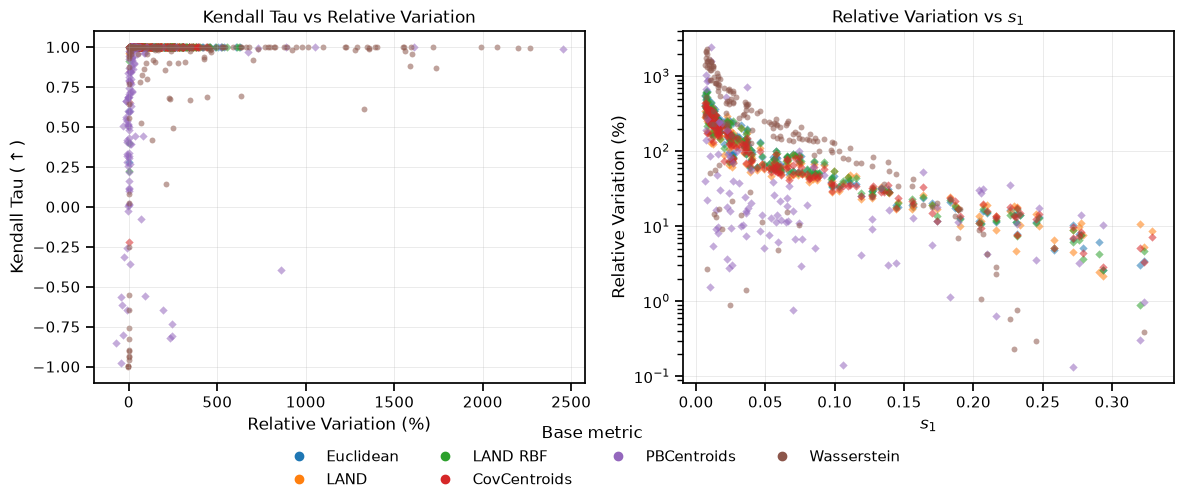

In [9]:
plot_data = df_extra.loc[
    (df_extra["Finsler"] == True) | (df_extra["Base Metric"] == "Wasserstein")
].copy()

plot_data["Base Metric"] = pd.Categorical(
    plot_data["Base Metric"], categories=method_names, ordered=True
)
plot_data = plot_data.sort_values("Base Metric")
palette = dict(zip(method_names, sns.color_palette("tab10", len(method_names))))
markers = {False: "o", True: "D"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for _, row in plot_data.iterrows():
    name = str(row["Base Metric"])
    color = palette.get(name, "0.50")
    marker = markers[bool(row["Finsler"])]
    ax1.scatter(
        row["Relative Variation"],
        row["Kendall Tau"],
        s=18,
        c=[color],
        marker=marker,
        alpha=0.55,
        linewidths=0,
    )
    ax2.scatter(
        row["First Time"],
        row["Relative Variation"],
        s=18,
        c=[color],
        marker=marker,
        alpha=0.55,
        linewidths=0,
    )

ax1.set_title("Kendall Tau vs Relative Variation")
ax1.set_xlabel("Relative Variation (%)")
ax1.set_ylabel(r"Kendall Tau ($\uparrow$)")
ax1.grid(True, linewidth=0.5, alpha=0.35)
ax2.set_title(r"Relative Variation vs $s_1$")
ax2.set_xlabel(r"$s_1$")
ax2.set_ylabel("Relative Variation (%)")
ax2.grid(True, linewidth=0.5, alpha=0.35)
ax2.set_yscale("log")

handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        color=palette[name],
        markerfacecolor=palette[name],
        markersize=6,
        label=name,
    )
    for name in method_names
    if name in plot_data["Base Metric"].astype(str).values
]
if handles:
    fig.legend(
        handles=handles,
        title="Base metric",
        loc="lower center",
        ncol=min(4, len(handles)),
        frameon=False,
        bbox_to_anchor=(0.5, -0.02),
    )
fig.tight_layout(rect=(0, 0.08, 1, 1))
# fig.savefig(
#     "/home/tblanchard/phd/finsler_learning/src/finsler_learning/komatsuna_pipeline/s1_vs_rest_komatsuna.pdf",
#     dpi=300,
#     bbox_inches="tight",
# )
plt.show()

## Kendall Tau versus FWD

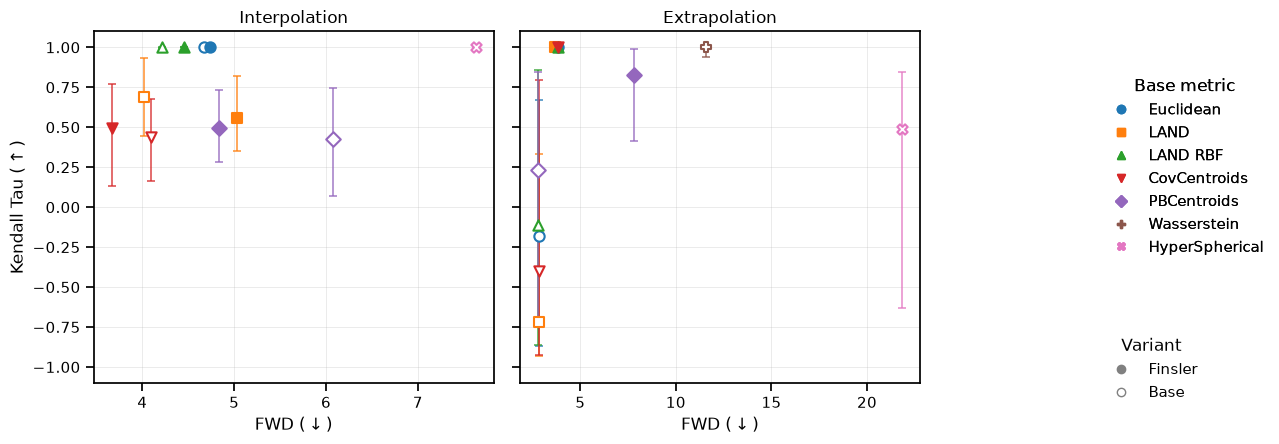

In [10]:
from matplotlib.lines import Line2D


def plot_base_tau_vs_fwd(combined, method_order=BASE_METHODS, save_path=None):
    combined = combined.copy()
    combined["Finsler"] = combined["Finsler"].astype(bool)

    method_names = [name for name, _ in method_order]
    combined["Base Metric"] = pd.Categorical(
        combined["Base Metric"], categories=method_names, ordered=True
    )
    combined = combined.sort_values(["Base Metric", "Finsler"])

    colors = dict(zip(method_names, sns.color_palette("tab10", len(method_names))))
    shapes = ["o", "s", "^", "v", "D", "P", "X", "<", ">", "h", "*", "p"]
    markers = {name: shapes[index % len(shapes)] for index, name in enumerate(method_names)}

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    panels = [
        ("Interpolation", "FWD Inter", "Kendall Tau Median Inter", "Kendall Tau IQR Inter"),
        ("Extrapolation", "FWD Extra", "Kendall Tau Median Extra", "Kendall Tau IQR Extra"),
    ]

    for ax, (title, fwd_column, tau_column, iqr_column) in zip(axes, panels):
        for _, row in combined.iterrows():
            x = pd.to_numeric(pd.Series([row[fwd_column]]), errors="coerce").iloc[0]
            y = pd.to_numeric(pd.Series([row[tau_column]]), errors="coerce").iloc[0]
            iqr = row[iqr_column]
            if pd.isna(x) or pd.isna(y) or not isinstance(iqr, tuple):
                continue

            low, high = iqr
            low = float(low)
            high = float(high)
            name = str(row["Base Metric"])
            color = colors.get(name, "0.50")

            ax.errorbar(
                x,
                y,
                yerr=[[max(0.0, y - low)], [max(0.0, high - y)]],
                fmt="none",
                ecolor=color,
                elinewidth=1.2,
                capsize=3,
                capthick=1.2,
                alpha=0.8,
                zorder=2,
            )
            ax.scatter(
                x,
                y,
                s=55,
                marker=markers.get(name, "o"),
                facecolor=color if bool(row["Finsler"]) else "white",
                edgecolor=color,
                linewidth=1.5,
                zorder=3,
            )

        ax.set_title(title)
        ax.set_xlabel(r"FWD ($\downarrow$)")
        ax.set_ylim(-1.1, 1.1)
        ax.grid(True, linewidth=0.5, alpha=0.35)

    axes[0].set_ylabel(r"Kendall Tau ($\uparrow$)")

    metric_handles = [
        Line2D([], [], marker=markers[name], linestyle="", color=colors[name], label=name)
        for name in method_names
        if name in combined["Base Metric"].astype(str).values
    ]
    variant_handles = [
        Line2D(
            [],
            [],
            marker="o",
            linestyle="",
            markerfacecolor="grey",
            markeredgecolor="grey",
            label="Finsler",
        ),
        Line2D(
            [],
            [],
            marker="o",
            linestyle="",
            markerfacecolor="white",
            markeredgecolor="grey",
            label="Base",
        ),
    ]

    leg1 = fig.legend(
        handles=metric_handles,
        title="Base metric",
        loc="center left",
        bbox_to_anchor=(1.0, 0.62),
        frameon=False,
    )
    fig.legend(
        handles=variant_handles,
        title="Variant",
        loc="center left",
        bbox_to_anchor=(1.0, 0.18),
        frameon=False,
    )
    fig.add_artist(leg1)

    fig.tight_layout(rect=(0, 0, 0.86, 1))
    if save_path:
        fig.savefig(save_path, bbox_inches="tight", dpi=300)
    return fig, axes


fig, axes = plot_base_tau_vs_fwd(
    combined,
    method_order=BASE_METHODS,
    # save_path="/home/tblanchard/phd/finsler_learning/src/finsler_learning/komatsuna_pipeline/scatter_plot_komatsuna.pdf",
    save_path=None,
)
plt.show()

## Biased extrapolation comparison

In [11]:
biased_extra, biased_quality = collect_biased_extrapolation(
    base_path,
    methods=METHODS,
)
biased_combined = merge_biased_extrapolation_table(
    biased_extra,
    biased_quality,
)
biased_combined

,Base Metric,Finsler,Biased,Kendall Tau Median Extra,Kendall Tau IQR Extra,Relative Variation Median Extra,Relative Variation IQR Extra,FWD Extra
0,CovCentroids,False,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",56.423996,"(27.172516345977783, 127.06061172485352)",3.574024
1,CovCentroids,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",73.910934,"(34.47526836395264, 179.6545753479004)",3.826219
2,Euclidean,False,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",87.430153,"(33.307416915893555, 232.08430862426758)",3.845692
3,Euclidean,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",86.491539,"(33.52425003051758, 234.2679100036621)",3.823045
4,LAND,False,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",70.685287,"(30.788716793060303, 184.4194107055664)",3.660202
5,LAND,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",70.746483,"(33.13239240646362, 187.55084991455078)",3.676467
6,LAND RBF,False,True,1.000000,"(0.9999999999999998, 0.9999999999999998)",78.128998,"(32.37438201904297, 210.6264419555664)",3.801677
7,LAND RBF,True,False,1.000000,"(0.9999999999999998, 0.9999999999999998)",83.718491,"(34.758734703063965, 226.52942657470703)",3.831601
8,PBCentroids,False,True,0.395811,"(-0.3789683644799335, 0.9666666666666665)",3.629669,"(-1.5985292196273804, 18.08724308013916)",7.119615
9,PBCentroids,True,False,0.826667,"(0.41619398549514197, 0.991654136491854)",10.259295,"(-0.3375161662697792, 30.076656341552734)",7.802444


In [12]:
biased_caption = (
    r"Extrapolation results on the Komatsuna dataset, comparing the Finsler metric "
    r"to a biased Riemannian sampling rule baseline. "
    r"Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$."
    r"Values are reported as median [IQR]."
)
biased_latex = biased_extrapolation_latex_table(
    biased_combined,
    caption=biased_caption,
    label="tab:riemannian_guided_komatsuna",
    method_order=METHODS,
)
print(biased_latex)

\begin{table}[ht]
\centering
\caption{Extrapolation results on the Komatsuna dataset, comparing the Finsler metric to a biased Riemannian sampling rule baseline. Here, $d=64, \alpha=5.0, \eta=0.999$, and $\zeta=0.9$.Values are reported as median [IQR].}
\label{tab:riemannian_guided_komatsuna}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llccc}
\toprule
    & & \multicolumn{3}{c}{Extrapolation} \\
    \cmidrule(lr){3-5}
    Base metric & Geometry
      & Kendall Tau ($\uparrow$) & Relative Variation (\%) & FWD ($\downarrow$) \\
\midrule
    \multirow{2}{*}{Euclidean} & Finsler & $1.00\,[1.00, 1.00]$ & $86.49\,[33.52, 234.27]$ & $3.82$ \\
     & Riemann (biased) & $1.00\,[1.00, 1.00]$ & $87.43\,[33.31, 232.08]$ & $3.85$ \\
\midrule
    \multirow{2}{*}{LAND} & Finsler & $1.00\,[1.00, 1.00]$ & $70.75\,[33.13, 187.55]$ & $3.68$ \\
     & Riemann (biased) & $1.00\,[1.00, 1.00]$ & $70.69\,[30.79, 184.42]$ & $3.66$ \\
\midrule
    \multirow{2}{*}{LAND RBF} & Finsler & $1.00\,[1.00, 1.00]$ & $83